# BÀI TẬP 06 — Cú sốc địa chính trị, chính sách kinh tế và lợi suất S&P 500

## Mở đầu: mục tiêu và cách tiếp cận

Bài viết kết hợp mô tả định tính có nguồn kiểm chứng với dữ liệu chuỗi thời gian hằng ngày. Mục tiêu là xem lợi suất trong các phiên được gán sự kiện có khác với mức dự đoán từ lợi suất phiên trước hay không:

$$Y_t=\ln(P_t/P_{t-1}),\qquad
Y_t=\beta_0+\beta_1Y_{t-1}+\beta_2D_t+\varepsilon_t.$$

$P_t$ là giá đóng cửa của chỉ số; $t$ đếm **phiên giao dịch**, không phải ngày lịch. Lợi suất này là lợi suất giá, không bao gồm cổ tức. Giả định làm việc là dữ liệu ngày/giá do người dùng cung cấp phản ánh đúng các phiên và giá đóng cửa. Việc chọn sự kiện được thực hiện hồi cứu; các sự kiện không phải thí nghiệm ngẫu nhiên. Giả định ngoại sinh cần cho diễn giải nhân quả chưa được xác lập, vì vậy kết quả được trình bày như **liên hệ thống kê có điều kiện**.

Nguồn tin xác nhận ngày và diễn biến; lợi suất được tính độc lập từ CSV. Bảng sự kiện được chốt trước khi chạy hồi quy và giữ cả sự kiện có lợi suất dương. Kết quả số và nhận xét phụ thuộc kết quả trong bài đều được sinh bằng code bên dưới.


In [1]:
from pathlib import Path
import sys
import html
import platform

import numpy as np
import pandas as pd
import scipy
from scipy.stats import norm
import statsmodels
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown, HTML

ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "sp500.csv").is_file() and (p / "script" / "preprocessing.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục dự án hoặc thư mục notebook.")
sys.path.insert(0, str(ROOT / "script"))
from preprocessing import (
    load_market, assign_events, preprocess, OUTPUT_COLUMNS, EXPECTED_EVENTS,
    MIN_SESSION_GAP, OUTLIER_LOG_THRESHOLD, ASSIGNMENT_RULE,
)

if not (ROOT / "data" / "processed.csv").exists():
    preprocess(ROOT)
market, quality = load_market(ROOT / "data" / "sp500.csv")
df = pd.read_csv(ROOT / "data" / "processed.csv", parse_dates=["date"])
events = pd.read_csv(ROOT / "data" / "events.csv", parse_dates=["date", "date_assigned"])
df["event"] = df["event"].fillna("")
df["D"] = df["D"].astype(int)
sample = df.dropna(subset=["Y", "Y_lag1"]).copy().reset_index(drop=True)
ALPHA, HAC_LAGS, MIN_TRAIN = 0.05, 5, 100
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 120, "axes.grid": True,
                     "grid.alpha": 0.22, "font.size": 10})
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda v: f"{v:.6f}")

def table(data, decimals=6):
    rendered = data.copy()
    for col in rendered.columns:
        if col == "p-value" or str(col).startswith("p "):
            rendered[col] = rendered[col].map(lambda v: fmt_p(v) if pd.notna(v) else "?")
    display(HTML(rendered.to_html(index=False, escape=True, float_format=lambda x: f"{x:.{decimals}f}")))

def fmt_p(value):
    value = float(value)
    return "x?p x? 0 ? ?? ch?nh x?c s? m?y" if value == 0 else f"{value:.4g}"

def rmse(errors):
    return float(np.sqrt(np.mean(np.square(np.asarray(errors, dtype=float)))))

display(Markdown(
    f"Dữ liệu có **{len(df):,} phiên**, từ **{df.date.min():%d/%m/%Y}** đến "
    f"**{df.date.max():%d/%m/%Y}**; mẫu hồi quy còn **{len(sample):,} quan sát** sau "
    f"khi bỏ missing do tạo lợi suất và độ trễ. Tập sự kiện có **{len(events)} mốc**, "
    f"tương ứng **{int(df.D.sum())} phiên D=1**."
))


Dữ liệu có **945 phiên**, từ **03/01/2023** đến **08/10/2026**; mẫu hồi quy còn **943 quan sát** sau khi bỏ missing do tạo lợi suất và độ trễ. Tập sự kiện có **5 mốc**, tương ứng **5 phiên D=1**.

# Phần 1 — Xử lý dữ liệu

## 1.1. Nguồn, khoảng thời gian và đơn vị

CSV giá gốc từ Investing.com do người dùng cung cấp được sao chép sang tên chuẩn của đề bài; không tải lại. Reuters được đọc qua các bài đăng lại có byline Reuters tại Investing.com; nguồn kiểm chứng thứ hai là AP News. Ngày tải tệp giá ban đầu không được ghi trong dữ liệu nên không suy đoán.

$$R_t=P_t/P_{t-1}-1=\exp(Y_t)-1.$$

Các phép tính dùng $Y_t$ ở đơn vị gốc; bảng và biểu đồ có thể hiển thị $100Y_t$ hoặc $100R_t$, với nhãn đơn vị rõ ràng.


In [2]:
source_summary = pd.DataFrame([
    {"Bộ dữ liệu": "Giá S&P 500", "Nguồn": "Investing.com — tệp do người dùng cung cấp",
     "Tệp": "data/sp500.csv", "Ngày đầu": f"{df.date.min():%d/%m/%Y}",
     "Ngày cuối": f"{df.date.max():%d/%m/%Y}", "Số dòng": len(df)},
    {"Bộ dữ liệu": "Sự kiện", "Nguồn": "Reuters và AP — URL đã mở/đọc",
     "Tệp": "data/events.csv", "Ngày đầu": f"{events.date.min():%d/%m/%Y}",
     "Ngày cuối": f"{events.date.max():%d/%m/%Y}", "Số dòng": len(events)},
    {"Bộ dữ liệu": "Mẫu hồi quy", "Nguồn": "Tính từ giá và bảng sự kiện",
     "Tệp": "data/processed.csv", "Ngày đầu": f"{sample.date.min():%d/%m/%Y}",
     "Ngày cuối": f"{sample.date.max():%d/%m/%Y}", "Số dòng": len(sample)},
])
table(source_summary)
table(pd.DataFrame({"Biến": ["price", "Y", "Y_lag1", "D"],
                    "Nội dung": ["Giá đóng cửa, điểm chỉ số", "Lợi suất log, đơn vị gốc",
                                 "Lợi suất log phiên liền trước", "Dummy của phiên sự kiện"]}))


Bộ dữ liệu,Nguồn,Tệp,Ngày đầu,Ngày cuối,Số dòng
Giá S&P 500,Investing.com — tệp do người dùng cung cấp,data/sp500.csv,03/01/2023,08/10/2026,945
Sự kiện,Reuters và AP — URL đã mở/đọc,data/events.csv,24/06/2023,28/02/2026,5
Mẫu hồi quy,Tính từ giá và bảng sự kiện,data/processed.csv,05/01/2023,08/10/2026,943


Biến,Nội dung
price,"Giá đóng cửa, điểm chỉ số"
Y,"Lợi suất log, đơn vị gốc"
Y_lag1,Lợi suất log phiên liền trước
D,Dummy của phiên sự kiện


## 1.2. Kiểm tra dữ liệu và quy tắc xử lý

Ngày đầu vào được parse theo MM/DD/YYYY; dấu phẩy phân cách hàng nghìn được bỏ trước khi chuyển số. Khối lượng có hậu tố K/M được chuyển theo nghìn/triệu, còn missing được giữ nguyên. Dữ liệu được sắp tăng dần, loại bản ghi trùng hoàn toàn và dừng nếu cùng ngày có thông tin giá mâu thuẫn hoặc thiếu/sai ngày, giá đóng cửa.

$$Y_t=\ln(P_t/P_{t-1}),\qquad Y_{\mathrm{lag1},t}=Y_{t-1}.$$

Không nội suy giá và không điền khối lượng bằng không. Biến động lớn là cờ sàng lọc; loại các phiên đó có thể làm mất cú sốc đang nghiên cứu. Missing ở đầu chuỗi do công thức được giữ trong tệp xuất, sau đó loại riêng khi lập mẫu mô hình. Lịch giao dịch là các ngày quan sát có trong CSV; nếu nguồn giá thiếu một phiên thì quy tắc gán cũng có thể bị ảnh hưởng.


In [3]:
validation = pd.DataFrame([
    {"Kiểm tra": "Dòng gốc", "Kết quả": quality["so_dong_goc"]},
    {"Kiểm tra": "Bản ghi trùng hoàn toàn", "Kết quả": quality["ban_ghi_trung_hoan_toan"]},
    {"Kiểm tra": "Ngày trùng sau parse", "Kết quả": quality["ngay_trung_sau_parse"]},
    {"Kiểm tra": "Dòng sau làm sạch", "Kết quả": quality["so_dong_sau_lam_sach"]},
    {"Kiểm tra": "Ngày cuối tuần trong CSV", "Kết quả": quality["so_ngay_cuoi_tuan_trong_csv"]},
    {"Kiểm tra": "Bất nhất OHLC", "Kết quả": quality["so_bat_nhat_ohlc"]},
    {"Kiểm tra": "Phiên biến động lớn được giữ", "Kết quả": len(quality["bien_dong_lon_giu_nguyen"])},
])
table(validation)
table(pd.DataFrame({"Cột gốc": list(quality["missing_du_lieu_goc"]),
                    "Missing trước xử lý": list(quality["missing_du_lieu_goc"].values())}))
table(pd.DataFrame({"Biến sau xử lý": list(quality["missing_sau_parse"]),
                    "Missing sau xử lý": list(quality["missing_sau_parse"].values())}))
large_moves = market.loc[market.Y.abs() > OUTLIER_LOG_THRESHOLD, ["date", "price", "Y"]].copy()
large_moves["100Y (%)"] = 100 * large_moves.pop("Y")
table(large_moves)
display(Markdown(
    f"Ngưỡng sàng lọc là $|Y_t|>{OUTLIER_LOG_THRESHOLD:.2f}$ "
    f"(tức $|100Y_t|>{100 * OUTLIER_LOG_THRESHOLD:.1f}$%). "
    f"Giữ nguyên **{len(large_moves)} phiên** vượt ngưỡng. "
    f"Cột khối lượng thiếu **{quality['missing_sau_parse']['volume']:,}/{len(market):,}** "
    "quan sát và không được sử dụng làm biến giải thích."
))


Kiểm tra,Kết quả
Dòng gốc,945
Bản ghi trùng hoàn toàn,0
Ngày trùng sau parse,0
Dòng sau làm sạch,945
Ngày cuối tuần trong CSV,0
Bất nhất OHLC,0
Phiên biến động lớn được giữ,2


Cột gốc,Missing trước xử lý
Date,0
Price,0
Open,0
High,0
Low,0
Vol.,945
Change %,0


Biến sau xử lý,Missing sau xử lý
date,0
price,0
open,0
high,0
low,0
volume,945
change_pct,0
Y,1
Y_lag1,2


date,price,100Y (%)
2025-04-04,5074.080000,-6.160907
2025-04-09,5456.900000,9.089490


Ngưỡng sàng lọc là $|Y_t|>0.05$ (tức $|100Y_t|>5.0$%). Giữ nguyên **2 phiên** vượt ngưỡng. Cột khối lượng thiếu **945/945** quan sát và không được sử dụng làm biến giải thích.

## 1.3. Bảng sự kiện, nguồn và cách chọn

$$D_t=\mathbf{1}\{t\text{ là phiên gán của một sự kiện được chọn}\}.$$

Ngày thực tế lưu ở cột **date**, ngày gán lưu riêng ở **date_assigned**. Giữ ngày giao dịch; cuối tuần/lễ chuyển sang phiên có trong CSV kế tiếp. Không thay ngày thực tế bằng ngày thị trường giảm. Hai nguồn của mỗi dòng xác nhận mốc sự kiện; các lợi suất bên dưới được tính từ giá, không lấy từ báo.

Wagner được định nghĩa cụ thể là mốc chiếm sở chỉ huy Rostov và tiến về Moskva, tách khỏi khởi đầu nổi loạn. Thuế Trung Quốc dùng ngày công bố, không dùng ngày có hiệu lực. Cuộc tấn công Iran năm 2026 dùng ngày bắt đầu được nguồn xác nhận.

Ưu tiên ngày có lợi suất âm và chọn hồi cứu gây **thiên lệch theo biến kết quả**, làm hệ số sự kiện có xu hướng âm. Sự kiện năm 2026 được giữ dù lợi suất dương để trải đều các năm. Một số cuộc tấn công/biện pháp trả đũa đã có cảnh báo: tính bất ngờ về mức độ hoặc thời điểm không đồng nghĩa hoàn toàn không thể dự đoán. Nhật ký đầy đủ: [events_research.md](../data/events_research.md).


In [4]:
price_returns = df[["date", "price", "Y", "D"]].copy()
price_returns["price_previous"] = df.price.shift(1)
event_data = events.merge(price_returns, left_on="date_assigned", right_on="date",
                          suffixes=("", "_trading"), validate="one_to_one").sort_values("date")
event_data["Mã"] = [f"E{i + 1}" for i in range(len(event_data))]
event_data["100Y (%)"] = 100 * event_data.Y
event_data["Lợi suất đơn (%)"] = 100 * np.expm1(event_data.Y)
event_display = pd.DataFrame({
    "Mã": event_data["Mã"], "Ngày thực tế": event_data.date.dt.strftime("%d/%m/%Y"),
    "Ngày gán D": event_data.date_assigned.dt.strftime("%d/%m/%Y"),
    "Sự kiện": event_data.event, "Giá phiên trước": event_data.price_previous,
    "Giá phiên gán": event_data.price, "100Y (%)": event_data["100Y (%)"],
    "Lợi suất đơn (%)": event_data["Lợi suất đơn (%)"],
    "Nguồn Reuters": event_data.source_url.map(lambda u: f'<a href="{html.escape(u, quote=True)}">Reuters</a>'),
    "Nguồn AP": event_data.source_url_2.map(lambda u: f'<a href="{html.escape(u, quote=True)}">AP</a>'),
})
safe_display = event_display.copy()
for col in ["Mã", "Ngày thực tế", "Ngày gán D", "Sự kiện"]:
    safe_display[col] = safe_display[col].map(html.escape)
display(HTML(safe_display.to_html(index=False, escape=False, float_format=lambda x: f"{x:.6f}")))
event_positions = pd.DatetimeIndex(df.date).get_indexer(events.date_assigned)
gaps = np.diff(np.sort(event_positions))
assert len(events) == EXPECTED_EVENTS and df.D.sum() == EXPECTED_EVENTS
assert (gaps >= MIN_SESSION_GAP).all() and event_data.D.eq(1).all()
display(Markdown(
    f"Quy tắc: **{ASSIGNMENT_RULE}** Khoảng cách phiên liên tiếp là "
    f"**{', '.join(map(str, gaps))}**, nhỏ nhất **{int(gaps.min())} phiên**. "
    f"Có **{int((event_data.Y < 0).sum())} phiên lợi suất âm** và "
    f"**{int((event_data.Y >= 0).sum())} phiên không âm**; giữ nguyên tập sự kiện."
))


Mã,Ngày thực tế,Ngày gán D,Sự kiện,Giá phiên trước,Giá phiên gán,100Y (%),Lợi suất đơn (%),Nguồn Reuters,Nguồn AP
E1,24/06/2023,26/06/2023,Wagner chiếm sở chỉ huy quân sự tại Rostov-on-Don và tiến về Moskva,4348.330000,4328.820000,-0.449688,-0.448678,Reuters,AP
E2,13/04/2024,15/04/2024,Iran mở cuộc tấn công trực tiếp bằng drone và tên lửa vào Israel,5123.410000,5061.820000,-1.209413,-1.202129,Reuters,AP
E3,01/10/2024,01/10/2024,Iran phóng tên lửa đạn đạo vào Israel,5762.480000,5708.750000,-0.936785,-0.932411,Reuters,AP
E4,04/04/2025,04/04/2025,Trung Quốc công bố thuế trả đũa 34% đối với hàng Mỹ,5396.520000,5074.080000,-6.160907,-5.974962,Reuters,AP
E5,28/02/2026,02/03/2026,Mỹ và Israel mở cuộc tấn công vào Iran,6878.880000,6881.620000,0.039824,0.039832,Reuters,AP


Quy tắc: **Giữ ngày có trong CSV; ngày không giao dịch gán phiên kế tiếp trong CSV.** Khoảng cách phiên liên tiếp là **202, 117, 127, 226**, nhỏ nhất **117 phiên**. Có **4 phiên lợi suất âm** và **1 phiên không âm**; giữ nguyên tập sự kiện.

## 1.4. Thống kê mô tả

$$\bar Y=\frac{1}{n}\sum_{t=1}^nY_t,\qquad
s_Y=\sqrt{\frac{\sum_t(Y_t-\bar Y)^2}{n-1}}.$$

Thống kê giá dùng tất cả các phiên; thống kê lợi suất dùng các phiên tính được lợi suất. So sánh nhóm sự kiện với nhóm còn lại chỉ mô tả sự khác biệt của mẫu đã chọn, chưa điều chỉnh lợi suất trễ hay tin khác cùng ngày.


In [5]:
descriptive = pd.DataFrame({
    "Giá (điểm chỉ số)": df.price.describe(),
    "100Y (%)": (100 * df.Y.dropna()).describe(),
    "100Y_lag1 (%)": (100 * df.Y_lag1.dropna()).describe(),
}).rename_axis("Thống kê").reset_index()
table(descriptive)
group_stats = df.dropna(subset=["Y"]).groupby("D").Y.agg(["count", "mean", "std", "min", "max"]).reset_index()
group_stats["Nhóm"] = group_stats.D.map({0: "Phiên còn lại", 1: "Phiên sự kiện"})
group_stats = group_stats.drop(columns="D")
for col in ["mean", "std", "min", "max"]:
    group_stats[col] *= 100
group_stats = group_stats.rename(columns={"count": "Số phiên", "mean": "Trung bình 100Y (%)",
    "std": "Độ lệch chuẩn 100Y (%)", "min": "Nhỏ nhất 100Y (%)", "max": "Lớn nhất 100Y (%)"})
table(group_stats[["Nhóm", "Số phiên", "Trung bình 100Y (%)", "Độ lệch chuẩn 100Y (%)",
                   "Nhỏ nhất 100Y (%)", "Lớn nhất 100Y (%)"]])
mean_event = df.loc[df.D.eq(1), "Y"].mean()
mean_other = df.loc[df.D.eq(0), "Y"].mean()
display(Markdown(
    f"Trung bình lợi suất log của nhóm sự kiện là **{100 * mean_event:.4f}%**, "
    f"so với **{100 * mean_other:.4f}%** của các phiên còn lại; "
    f"chênh lệch mô tả là **{100 * (mean_event - mean_other):.4f} điểm phần trăm**."
))


Thống kê,Giá (điểm chỉ số),100Y (%),100Y_lag1 (%)
count,945.000000,944.000000,943.000000
mean,5707.893122,0.075036,0.075612
std,1120.149549,0.921896,0.922216
min,3808.100000,-6.160907,-6.160907
25%,4622.440000,-0.375329,-0.374396
50%,5699.940000,0.090483,0.090687
75%,6664.010000,0.581607,0.582145
max,7818.930000,9.089490,9.089490


Nhóm,Số phiên,Trung bình 100Y (%),Độ lệch chuẩn 100Y (%),Nhỏ nhất 100Y (%),Lớn nhất 100Y (%)
Phiên còn lại,939,0.084719,0.899848,-4.960588,9.089490
Phiên sự kiện,5,-1.743394,2.515140,-6.160907,0.039824


Trung bình lợi suất log của nhóm sự kiện là **-1.7434%**, so với **0.0847%** của các phiên còn lại; chênh lệch mô tả là **-1.8281 điểm phần trăm**.

### Biểu đồ giá và lợi suất có đánh dấu sự kiện

Đường giá thể hiện mức chỉ số; đường lợi suất thể hiện thay đổi giữa hai phiên liên tiếp:

$$100Y_t=100\ln(P_t/P_{t-1}).$$

Các mã sự kiện trên biểu đồ tương ứng bảng nguồn ở mục trước. Biểu đồ giúp nhận diện biến động, không tự xác định nguyên nhân của từng phiên.


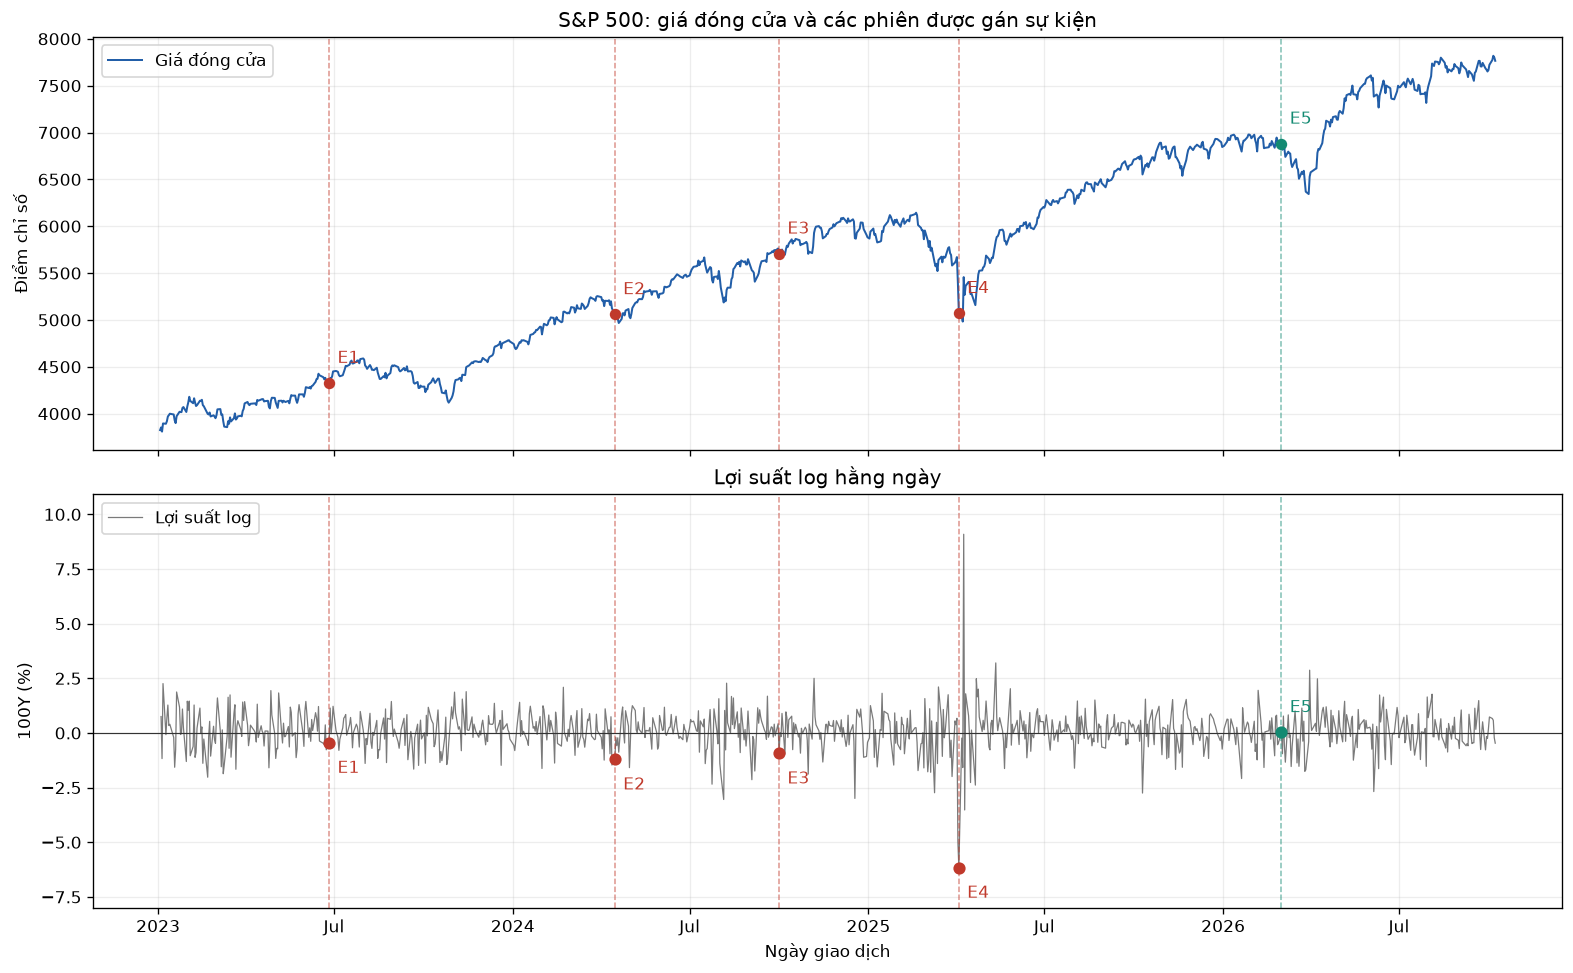

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, layout="constrained")
axes[0].plot(df.date, df.price, color="#225ea8", linewidth=1.2, label="Giá đóng cửa")
axes[1].plot(df.date, 100 * df.Y, color="#636363", linewidth=0.75, alpha=0.85, label="Lợi suất log")
axes[1].axhline(0, color="#333333", linewidth=0.7)
for row in event_data.itertuples(index=False):
    color = "#c0392b" if row.Y < 0 else "#138a72"
    for ax in axes:
        ax.axvline(row.date_assigned, color=color, linewidth=0.9, alpha=0.55, linestyle="--")
    axes[0].scatter(row.date_assigned, row.price, color=color, s=34, zorder=3)
    axes[1].scatter(row.date_assigned, 100 * row.Y, color=color, s=40, zorder=3)
    event_id = getattr(row, "Mã")
    axes[0].annotate(event_id, (row.date_assigned, row.price), xytext=(5, 12),
                     textcoords="offset points", color=color)
    axes[1].annotate(event_id, (row.date_assigned, 100 * row.Y),
                     xytext=(5, -18 if row.Y < 0 else 12), textcoords="offset points", color=color)
axes[0].set(title="S&P 500: giá đóng cửa và các phiên được gán sự kiện", ylabel="Điểm chỉ số")
axes[1].set(title="Lợi suất log hằng ngày", ylabel="100Y (%)", xlabel="Ngày giao dịch")
axes[1].xaxis.set_major_locator(mdates.AutoDateLocator())
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(axes[1].xaxis.get_major_locator()))
axes[1].margins(y=0.12)
for ax in axes:
    ax.legend(loc="upper left")
plt.show()


# Phần 2 — Mô hình chuỗi thời gian

## 2.1. Kiểm định ADF cho lợi suất

ADF kiểm tra $H_0$: chuỗi có nghiệm đơn vị, với phương trình có hằng số:

$$\Delta Y_t=\alpha+\gamma Y_{t-1}
+\sum_{j=1}^{p}\delta_j\Delta Y_{t-j}+u_t.$$

Độ trễ được chọn theo AIC trong miền tối đa mặc định của statsmodels. Bác bỏ $H_0$ hỗ trợ dùng lợi suất làm chuỗi dừng trong mô hình, nhưng không chứng minh phương sai không đổi hay loại trừ đứt gãy cấu trúc.


In [7]:
adf_stat, adf_p, adf_lags, adf_n, adf_critical, adf_aic = adfuller(
    df.Y.dropna(), regression="c", autolag="AIC"
)
table(pd.DataFrame([{"Thống kê ADF": adf_stat, "p-value": adf_p,
    "Độ trễ AIC": adf_lags, "Số quan sát kiểm định": adf_n, "AIC tốt nhất": adf_aic}]))
table(pd.DataFrame({"Mức": list(adf_critical), "Giá trị tới hạn": list(adf_critical.values())}))
adf_decision = "bác bỏ" if adf_p < ALPHA else "chưa bác bỏ"
display(Markdown(
    f"ADF có thống kê **{adf_stat:.4f}**, p-value **{fmt_p(adf_p)}**, "
    f"độ trễ **{adf_lags}**. Với mức ý nghĩa **{100 * ALPHA:.0f}%**, "
    f"**{adf_decision} giả thuyết nghiệm đơn vị**. "
    + ("Kết quả hỗ trợ giả định dừng của lợi suất trong mẫu."
       if adf_p < ALPHA else "Bằng chứng về tính dừng chưa đủ; kết quả OLS cần đọc thận trọng.")
))


Thống kê ADF,p-value,Độ trễ AIC,Số quan sát kiểm định,AIC tốt nhất
-17.126983,7.192e-30,3,940,-6029.167695


Mức,Giá trị tới hạn
1%,-3.437326
5%,-2.864620
10%,-2.568410


ADF có thống kê **-17.1270**, p-value **7.192e-30**, độ trễ **3**. Với mức ý nghĩa **5%**, **bác bỏ giả thuyết nghiệm đơn vị**. Kết quả hỗ trợ giả định dừng của lợi suất trong mẫu.

## 2.2. Ước lượng mô hình AR(1) có dummy sự kiện

$$Y_t=\beta_0+\beta_1Y_{t-1}+\beta_2D_t+\varepsilon_t,
\qquad \hat\beta=(X'X)^{-1}X'Y.$$

$\beta_1$ mô tả liên hệ với phiên trước; $\beta_2$ là chênh lệch lợi suất log giữa phiên sự kiện và phiên khác, giữ lợi suất trễ cố định. Mẫu hồi quy loại missing ở $Y_t$ và $Y_{t-1}$, giữ tất cả các phiên sự kiện. OLS trước hết ước lượng hệ số; độ tin cậy suy luận được xem lại bằng chẩn đoán và HAC.


In [8]:
X = sm.add_constant(sample[["Y_lag1", "D"]], has_constant="add")
ols = sm.OLS(sample.Y, X, missing="raise").fit()
assert int(sample.D.sum()) == EXPECTED_EVENTS
table(pd.DataFrame([{"Số quan sát": int(ols.nobs), "Số tham số": len(ols.params),
    "R bình phương": ols.rsquared, "R bình phương hiệu chỉnh": ols.rsquared_adj,
    "RMSE lợi suất log": rmse(ols.resid), "AIC": ols.aic, "BIC": ols.bic}]))
display(ols.summary())
display(Markdown(
    f"Ước lượng AR(1) là **{ols.params['Y_lag1']:.6f}**; "
    f"$|\\hat\\beta_1|$ **{'nhỏ hơn' if abs(ols.params['Y_lag1']) < 1 else 'không nhỏ hơn'} 1**. "
    "R bình phương thấp ở lợi suất hằng ngày không tự phủ nhận các cú sốc; "
    "mô hình chỉ mô tả một phần nhỏ thông tin thị trường."
))


Số quan sát,Số tham số,R bình phương,R bình phương hiệu chỉnh,RMSE lợi suất log,AIC,BIC
943,3,0.023532,0.021455,0.009107,-6179.602292,-6165.055093


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.024
Model:                            OLS   Adj. R-squared:                  0.021
Method:                 Least Squares   F-statistic:                     11.33
Date:                Fri, 09 Oct 2026   Prob (F-statistic):           1.38e-05
Time:                        10:59:50   Log-Likelihood:                 3092.8
No. Observations:                 943   AIC:                            -6180.
Df Residuals:                     940   BIC:                            -6165.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0009      0.000      2.958      0.003       0.000       0.001
Y_lag1        -0.0533      0.032     -1.641      0.101      -0.117       0.010
D             -0.0191      0.004     -4.633      0.000      -0.027      -0.011
==============================================================================
Omnibus:                      218.732   Durbin-Watson:                   1.998
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             5023.639
Skew:                           0.456   Prob(JB):                         0.00
Kurtosis:                      14.270   Cond. No.                         109.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Ước lượng AR(1) là **-0.053273**; $|\hat\beta_1|$ **nhỏ hơn 1**. R bình phương thấp ở lợi suất hằng ngày không tự phủ nhận các cú sốc; mô hình chỉ mô tả một phần nhỏ thông tin thị trường.

## 2.3. Chẩn đoán phần dư

Durbin–Watson mô tả tự tương quan ngắn hạn:

$$DW=\frac{\sum_{t=2}^{n}(\hat\varepsilon_t-\hat\varepsilon_{t-1})^2}
{\sum_{t=1}^{n}\hat\varepsilon_t^2}.$$

Ljung–Box kiểm tra tự tương quan gộp, Jarque–Bera kiểm tra chuẩn tính qua độ lệch và độ nhọn, ARCH-LM kiểm tra tính phụ thuộc của phương sai:

$$Q(h)=n(n+2)\sum_{k=1}^{h}\frac{\hat\rho_k^2}{n-k},\quad
JB=\frac n6\left(S^2+\frac{(K-3)^2}{4}\right),\quad LM_{\mathrm{ARCH}}=nR^2.$$

Ljung–Box hiệu chỉnh một bậc tự do cho thành phần AR(1); ARCH hiệu chỉnh số tham số hồi quy. DW chỉ dùng mô tả vì mô hình có biến phụ thuộc trễ. Các kiểm định có thể chịu ảnh hưởng của đuôi dày và mẫu sự kiện nhỏ.


Kiểm định,Thống kê,p-value,Nhận xét
Durbin–Watson (mô tả),1.998428,?,Không dùng p-value DW để suy luận với Y trễ
"Ljung–Box, h=10",12.392635,0.1921,Chưa bác bỏ không tự tương quan
"Ljung–Box, h=20",27.455685,0.09448,Chưa bác bỏ không tự tương quan
Jarque–Bera,5023.638575,x?p x? 0 ? ?? ch?nh x?c s? m?y,Bác bỏ chuẩn tính
"ARCH-LM, q=5",103.895221,7.973e-21,Bác bỏ không ARCH


DW = **1.9984**; độ lệch phần dư **0.4563**, độ nhọn **14.2704**. Jarque–Bera có p-value **x?p x? 0 ? ?? ch?nh x?c s? m?y** và ARCH-LM có p-value **7.973e-21**. Các nhận xét trong bảng dùng cùng mức ý nghĩa đã khai báo. HAC điều chỉnh suy luận trước tự tương quan và phương sai thay đổi, nhưng không xử lý thiên lệch chọn sự kiện hay biến bị bỏ sót.

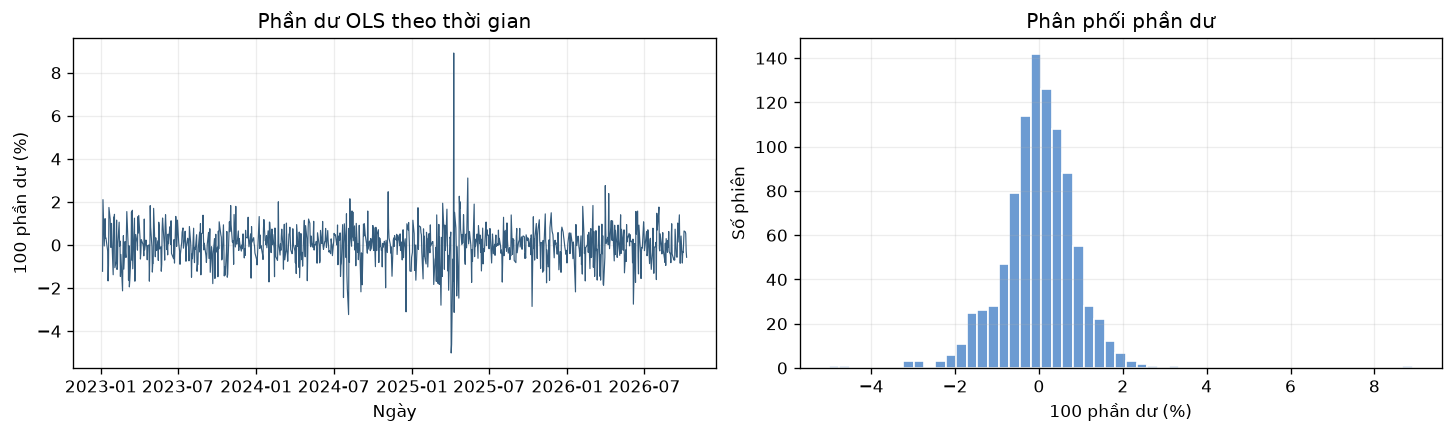

In [9]:
residuals = ols.resid
dw = durbin_watson(residuals)
lb_lags = [10, 20]
lb = acorr_ljungbox(residuals, lags=lb_lags, model_df=1, return_df=True)
jb_stat, jb_p, skewness, kurtosis = jarque_bera(residuals)
arch_lags = 5
arch_lm, arch_p, arch_f, arch_fp = het_arch(residuals, nlags=arch_lags, ddof=len(ols.params))
diagnostics = pd.DataFrame([
    {"Kiểm định": "Durbin–Watson (mô tả)", "Thống kê": dw, "p-value": np.nan,
     "Nhận xét": "Không dùng p-value DW để suy luận với Y trễ"},
    *[{"Kiểm định": f"Ljung–Box, h={h}", "Thống kê": lb.loc[h, "lb_stat"],
       "p-value": lb.loc[h, "lb_pvalue"],
       "Nhận xét": "Bác bỏ không tự tương quan" if lb.loc[h, "lb_pvalue"] < ALPHA
                   else "Chưa bác bỏ không tự tương quan"} for h in lb_lags],
    {"Kiểm định": "Jarque–Bera", "Thống kê": jb_stat, "p-value": jb_p,
     "Nhận xét": "Bác bỏ chuẩn tính" if jb_p < ALPHA else "Chưa bác bỏ chuẩn tính"},
    {"Kiểm định": f"ARCH-LM, q={arch_lags}", "Thống kê": arch_lm, "p-value": arch_p,
     "Nhận xét": "Bác bỏ không ARCH" if arch_p < ALPHA else "Chưa bác bỏ không ARCH"},
])
table(diagnostics)
display(Markdown(
    f"DW = **{dw:.4f}**; độ lệch phần dư **{skewness:.4f}**, độ nhọn **{kurtosis:.4f}**. "
    f"Jarque–Bera có p-value **{fmt_p(jb_p)}** và ARCH-LM có p-value **{fmt_p(arch_p)}**. "
    "Các nhận xét trong bảng dùng cùng mức ý nghĩa đã khai báo. "
    "HAC điều chỉnh suy luận trước tự tương quan và phương sai thay đổi, "
    "nhưng không xử lý thiên lệch chọn sự kiện hay biến bị bỏ sót."
))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
axes[0].plot(sample.date, residuals * 100, linewidth=0.7, color="#355c7d")
axes[0].set(title="Phần dư OLS theo thời gian", ylabel="100 phần dư (%)", xlabel="Ngày")
axes[1].hist(residuals * 100, bins=55, color="#6c9bd2", edgecolor="white")
axes[1].set(title="Phân phối phần dư", xlabel="100 phần dư (%)", ylabel="Số phiên")
plt.show()


### Sai số chuẩn Newey–West

Với $g_t=x_t\hat\varepsilon_t$, ước lượng HAC dùng trọng số Bartlett:

$$\widehat V_{\mathrm{HAC}}=(X'X)^{-1}
\left[\sum_tg_tg_t'+\sum_{\ell=1}^{L}w_\ell
\sum_{t=\ell+1}^{n}(g_tg_{t-\ell}'+g_{t-\ell}g_t')\right](X'X)^{-1},
\quad w_\ell=1-\frac{\ell}{L+1}.$$

Code áp dụng thêm hiệu chỉnh hữu hạn $n/(n-k)$. Chọn độ trễ HAC theo kế hoạch trước ước lượng, không chọn theo p-value. Hệ số vẫn là OLS; chỉ covariance, sai số chuẩn và suy luận thay đổi. Tài liệu: [statsmodels HAC](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.get_robustcov_results.html).


In [10]:
hac = ols.get_robustcov_results(cov_type="HAC", maxlags=HAC_LAGS,
                               use_correction=True, use_t=False)
names = ols.model.exog_names
hac_se = pd.Series(hac.bse, index=names)
hac_p = pd.Series(hac.pvalues, index=names)
hac_ci = pd.DataFrame(hac.conf_int(alpha=ALPHA), index=names, columns=["lower", "upper"])
se_comparison = pd.DataFrame({
    "Biến": names, "Hệ số OLS": ols.params.to_numpy(), "SE thường": ols.bse.to_numpy(),
    "SE HAC": hac.bse, "p thường (t)": ols.pvalues.to_numpy(), "p HAC (chuẩn)": hac.pvalues,
})
table(se_comparison)
np.testing.assert_allclose(hac.params, ols.params)
display(Markdown(
    f"HAC dùng **{HAC_LAGS} độ trễ**, kernel Bartlett, hiệu chỉnh hữu hạn "
    "và phân phối chuẩn cho suy luận. Bảng kết quả chính và khoảng tin cậy dưới đây dùng HAC."
))


Biến,Hệ số OLS,SE thường,SE HAC,p thường (t),p HAC (chuẩn)
const,0.000885,0.000299,0.000286,0.003173,0.00195
Y_lag1,-0.053273,0.032462,0.055774,0.1011,0.3395
D,-0.019087,0.004120,0.010542,4.121e-06,0.07022


HAC dùng **5 độ trễ**, kernel Bartlett, hiệu chỉnh hữu hạn và phân phối chuẩn cho suy luận. Bảng kết quả chính và khoảng tin cậy dưới đây dùng HAC.

# Phần 3 — Phân tích tác động

## 3.1. Bảng hệ số và diễn giải hệ số sự kiện

$$\beta_2=
E[Y_t\mid Y_{t-1}=y,D_t=1]-E[Y_t\mid Y_{t-1}=y,D_t=0]$$

là diễn giải của **mô hình tuyến tính có điều kiện**. Nhân hệ số với 100 để chuyển sang điểm phần trăm của lợi suất log. Đây không phải ước lượng nhân quả đã được nhận diện. P-value HAC quyết định cách viết nhận xét; không thay đổi sự kiện để đạt một dấu hoặc mức ý nghĩa mong muốn.


In [11]:
coefficient_table = pd.DataFrame({
    "Biến": names, "Hệ số": ols.params.to_numpy(), "SE HAC": hac_se.to_numpy(),
    "z HAC": hac.tvalues, "p HAC": hac_p.to_numpy(),
    "CI 95% dưới": hac_ci.lower.to_numpy(), "CI 95% trên": hac_ci.upper.to_numpy(),
})
table(coefficient_table)
beta2 = float(ols.params["D"])
beta2_se = float(hac_se["D"])
beta2_p = float(hac_p["D"])
effect_direction = "âm" if beta2 < 0 else ("dương" if beta2 > 0 else "bằng không")
effect_significance = "có" if beta2_p < ALPHA else "chưa có"
display(Markdown(
    f"$\\hat\\beta_2$ = **{beta2:.6f}**, dấu **{effect_direction}**; "
    f"tương ứng **{100 * beta2:.4f} điểm phần trăm lợi suất log mỗi phiên** "
    "khi giữ lợi suất phiên trước cố định. "
    f"P-value HAC = **{fmt_p(beta2_p)}**: **{effect_significance} ý nghĩa thống kê "
    f"ở mức {100 * ALPHA:.0f}%**. "
    "Kết quả này áp dụng cho tập phiên đã chọn; không chứng minh mọi tin địa chính trị "
    "đều gây giảm và không tách được tác động của các tin khác cùng phiên."
))


Biến,Hệ số,SE HAC,z HAC,p HAC,CI 95% dưới,CI 95% trên
const,0.000885,0.000286,3.097676,0.00195,0.000325,0.001444
Y_lag1,-0.053273,0.055774,-0.955154,0.3395,-0.162588,0.056042
D,-0.019087,0.010542,-1.810480,0.07022,-0.039749,0.001576


$\hat\beta_2$ = **-0.019087**, dấu **âm**; tương ứng **-1.9087 điểm phần trăm lợi suất log mỗi phiên** khi giữ lợi suất phiên trước cố định. P-value HAC = **0.07022**: **chưa có ý nghĩa thống kê ở mức 5%**. Kết quả này áp dụng cho tập phiên đã chọn; không chứng minh mọi tin địa chính trị đều gây giảm và không tách được tác động của các tin khác cùng phiên.

## 3.2. Khoảng tin cậy cho hệ số sự kiện

Với suy luận chuẩn HAC, khoảng tin cậy hai phía:

$$CI_{1-\alpha}(\beta_2)=
\hat\beta_2\pm z_{1-\alpha/2}\,SE_{\mathrm{HAC}}(\hat\beta_2).$$

Ở mức 95%, hệ số tới hạn xấp xỉ 1,96. Code tính phân vị chính xác, so sánh với kết quả statsmodels và kiểm tra khoảng có chứa không hay không. Khoảng này là xấp xỉ tiệm cận, cần thận trọng khi dummy chỉ xuất hiện ở rất ít phiên.


beta2,SE HAC,z tới hạn,CI dưới,CI trên,CI dưới (điểm % log),CI trên (điểm % log)
-0.019087,0.010542,1.959964,-0.039749,0.001576,-3.974893,0.157590


Khoảng tin cậy **95%** là **[-0.039749; 0.001576]**, hay **[-3.9749; 0.1576] điểm phần trăm lợi suất log**. Khoảng **chứa 0**, phù hợp với kết luận kiểm định HAC ở trên.

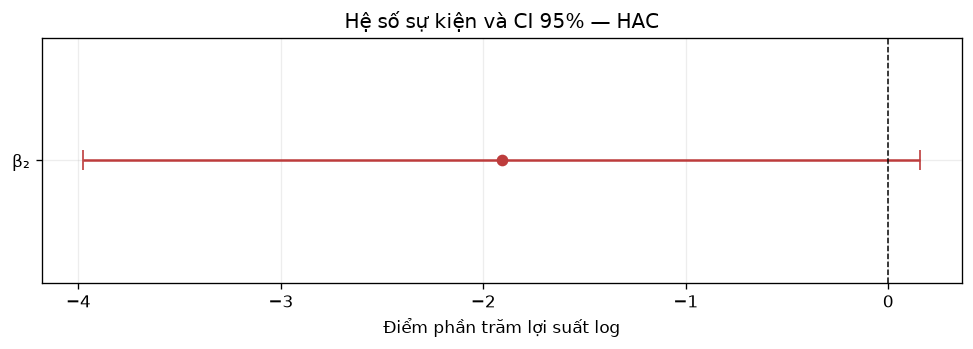

In [12]:
z_critical = float(norm.ppf(1 - ALPHA / 2))
ci_lower = beta2 - z_critical * beta2_se
ci_upper = beta2 + z_critical * beta2_se
np.testing.assert_allclose([ci_lower, ci_upper], hac_ci.loc["D"].to_numpy())
table(pd.DataFrame([{"beta2": beta2, "SE HAC": beta2_se, "z tới hạn": z_critical,
    "CI dưới": ci_lower, "CI trên": ci_upper,
    "CI dưới (điểm % log)": 100 * ci_lower, "CI trên (điểm % log)": 100 * ci_upper}]))
ci_contains_zero = ci_lower <= 0 <= ci_upper
display(Markdown(
    f"Khoảng tin cậy **{100 * (1 - ALPHA):.0f}%** là "
    f"**[{ci_lower:.6f}; {ci_upper:.6f}]**, hay "
    f"**[{100 * ci_lower:.4f}; {100 * ci_upper:.4f}] điểm phần trăm lợi suất log**. "
    f"Khoảng **{'chứa' if ci_contains_zero else 'không chứa'} 0**, "
    "phù hợp với kết luận kiểm định HAC ở trên."
))
fig, ax = plt.subplots(figsize=(8, 2.8), layout="constrained")
ax.errorbar(100 * beta2, 0, xerr=z_critical * 100 * beta2_se, fmt="o", capsize=6, color="#bd3c3c")
ax.axvline(0, color="black", linestyle="--", linewidth=0.9)
ax.set(yticks=[0], yticklabels=["β₂"], xlabel="Điểm phần trăm lợi suất log",
       title=f"Hệ số sự kiện và CI {100 * (1 - ALPHA):.0f}% — HAC")
plt.show()


## 3.3. So sánh AR(1) và AR(1) có sự kiện trong mẫu

Mô hình cơ sở bỏ dummy, ước lượng trên **cùng các phiên**:

$$Y_t=a_0+a_1Y_{t-1}+u_t,\qquad
RMSE=\sqrt{\frac1n\sum_t(Y_t-\hat Y_t)^2}.$$

So sánh RMSE toàn mẫu, nhóm sự kiện và nhóm còn lại; trình bày phần dư từng sự kiện. Đây là độ khớp **hồi cứu**: mô hình mở rộng đã biết dummy và được ước lượng trên cả mẫu. Thêm biến vào OLS có thể giảm tổng bình phương sai số một cách cơ học; giảm RMSE trong mẫu chưa chứng minh khả năng dự báo thực tế.


In [13]:
X_base = sm.add_constant(sample[["Y_lag1"]], has_constant="add")
baseline = sm.OLS(sample.Y, X_base, missing="raise").fit()
comparison = []
for label, mask in [("Toàn mẫu", np.ones(len(sample), dtype=bool)),
                    ("D=1", sample.D.eq(1)), ("D=0", sample.D.eq(0))]:
    comparison.append({"Nhóm": label, "Số phiên": int(np.sum(mask)),
        "RMSE AR(1) (log)": rmse(baseline.resid[mask]),
        "RMSE AR(1)+D (log)": rmse(ols.resid[mask]),
        "RMSE AR(1) (điểm % log)": 100 * rmse(baseline.resid[mask]),
        "RMSE AR(1)+D (điểm % log)": 100 * rmse(ols.resid[mask])})
fit_comparison = pd.DataFrame(comparison)
table(fit_comparison)
event_residuals = sample.loc[sample.D.eq(1), ["date", "event", "Y"]].copy()
event_residuals["Dự đoán AR(1)"] = baseline.fittedvalues.loc[event_residuals.index]
event_residuals["Dự đoán AR(1)+D"] = ols.fittedvalues.loc[event_residuals.index]
event_residuals["Phần dư AR(1)"] = baseline.resid.loc[event_residuals.index]
event_residuals["Phần dư AR(1)+D"] = ols.resid.loc[event_residuals.index]
for col in event_residuals.columns.difference(["date", "event"]):
    event_residuals[col] *= 100
table(event_residuals.rename(columns={"Y": "100Y (%)"}))
rmse_base = rmse(baseline.resid)
rmse_with_event = rmse(ols.resid)
rmse_improvement = 100 * (1 - rmse_with_event / rmse_base)
display(Markdown(
    f"RMSE toàn mẫu của AR(1) là **{rmse_base:.6f}**, của AR(1)+D là "
    f"**{rmse_with_event:.6f}** (đơn vị lợi suất log), "
    f"mức giảm tương đối **{rmse_improvement:.2f}%**. "
    "Phần dư trong bảng là thực tế trừ giá trị khớp, hiển thị theo điểm phần trăm log. "
    "Một hệ số chung không nhất thiết cải thiện sai số của từng sự kiện."
))


Nhóm,Số phiên,RMSE AR(1) (log),RMSE AR(1)+D (log),RMSE AR(1) (điểm % log),RMSE AR(1)+D (điểm % log)
Toàn mẫu,943,0.009211,0.009107,0.921062,0.910724
D=1,5,0.029738,0.023432,2.973807,2.343161
D=0,938,0.008976,0.008970,0.897628,0.896980


date,event,100Y (%),Dự đoán AR(1),Dự đoán AR(1)+D,Phần dư AR(1),Phần dư AR(1)+D
2023-06-26,Wagner chiếm sở chỉ huy quân sự tại Rostov-on-Don và tiến về Moskva,-0.449688,0.104045,-1.779227,-0.553732,1.329539
2024-04-15,Iran mở cuộc tấn công trực tiếp bằng drone và tên lửa vào Israel,-1.209413,0.128578,-1.742099,-1.337991,0.532686
2024-10-01,Iran phóng tên lửa đạn đạo vào Israel,-0.936785,0.062099,-1.842706,-0.998884,0.905921
2025-04-04,Trung Quốc công bố thuế trả đũa 34% đối với hàng Mỹ,-6.160907,0.251602,-1.555919,-6.412510,-4.604988
2026-03-02,Mỹ và Israel mở cuộc tấn công vào Iran,0.039824,0.092289,-1.797017,-0.052465,1.836841


RMSE toàn mẫu của AR(1) là **0.009211**, của AR(1)+D là **0.009107** (đơn vị lợi suất log), mức giảm tương đối **1.12%**. Phần dư trong bảng là thực tế trừ giá trị khớp, hiển thị theo điểm phần trăm log. Một hệ số chung không nhất thiết cải thiện sai số của từng sự kiện.

### Bổ sung: dự báo AR(1) cuốn chiếu ngoài mẫu

Tại mỗi phiên, chỉ dùng các quan sát trước phiên đó để ước lượng lại AR(1):

$$\hat Y_{t\mid t-1}=\hat a_{0,t-1}+\hat a_{1,t-1}Y_{t-1},\qquad
e_{t\mid t-1}=Y_t-\hat Y_{t\mid t-1}.$$

Cửa sổ mở rộng bắt đầu sau số quan sát huấn luyện tối thiểu đã khai báo. Không cung cấp $D_t$ của tin bất ngờ cho dự báo trước phiên. Báo cáo sai số từng sự kiện và so sánh với các phiên khác. Đây là bằng chứng về sai số quanh sự kiện, không quy toàn bộ sai số cho riêng tin đó; tập sự kiện vẫn được chọn hồi cứu.


Nhóm ngoài mẫu,Số phiên,RMSE (log),MAE (log),Trung bình sai số (log)
Toàn bộ,843,0.009224,0.006366,-0.000085
D=1,5,0.029023,0.018395,-0.018395
D=0,838,0.008976,0.006295,0.000024


date,event,Phiên huấn luyện cuối,Số phiên huấn luyện,100Y (%),Dự báo 100Y (%),Sai số (điểm % log),"|Sai số|, phân vị so với D=0 (%)"
2023-06-26,Wagner chiếm sở chỉ huy quân sự tại Rostov-on-Don và tiến về Moskva,2023-06-23,117,-0.449688,0.122647,-0.572335,57.875895
2024-04-15,Iran mở cuộc tấn công trực tiếp bằng drone và tên lửa vào Israel,2024-04-12,319,-1.209413,0.076273,-1.285686,88.066826
2024-10-01,Iran phóng tên lửa đạn đạo vào Israel,2024-09-30,436,-0.936785,0.098258,-1.035043,82.577566
2025-04-04,Trung Quốc công bố thuế trả đũa 34% đối với hàng Mỹ,2025-04-03,563,-6.160907,0.089007,-6.249914,99.880668
2026-03-02,Mỹ và Israel mở cuộc tấn công vào Iran,2026-02-27,789,0.039824,0.094392,-0.054568,7.040573


Huấn luyện ban đầu **100 quan sát**, dự báo **843 phiên**, từ **31/05/2023** đến **08/10/2026**. RMSE ngoài mẫu của nhóm sự kiện là **0.029023**, nhóm còn lại **0.008976**, tỷ số **3.234**. **Sai số lớn hơn ở nhóm sự kiện trong mẫu được chọn.** Không kết luận nhân quả từ tỷ số này; không xem AR(1)+D hồi cứu là dự báo có thể biết trước tin bất ngờ.

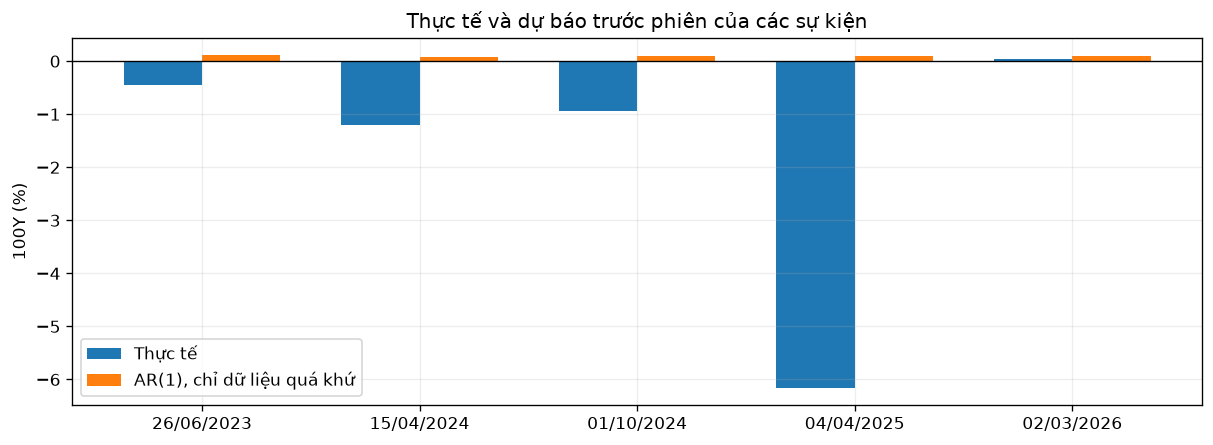

In [14]:
rolling_rows = []
for position in range(MIN_TRAIN, len(sample)):
    train = sample.iloc[:position]
    current = sample.iloc[position]
    assert train.date.max() < current.date
    fit_past = sm.OLS(train.Y, sm.add_constant(train[["Y_lag1"]], has_constant="add")).fit()
    predicted = float(fit_past.params["const"] + fit_past.params["Y_lag1"] * current.Y_lag1)
    rolling_rows.append({"date": current.date, "event": current.event, "D": int(current.D),
                         "actual": float(current.Y), "predicted": predicted,
                         "error": float(current.Y - predicted),
                         "train_end": train.date.max(), "train_n": len(train)})
rolling = pd.DataFrame(rolling_rows)
assert (rolling.train_end < rolling.date).all()
assert int(rolling.D.sum()) == EXPECTED_EVENTS
rolling_summary = pd.DataFrame([
    {"Nhóm ngoài mẫu": label, "Số phiên": int(mask.sum()),
     "RMSE (log)": rmse(rolling.loc[mask, "error"]),
     "MAE (log)": float(rolling.loc[mask, "error"].abs().mean()),
     "Trung bình sai số (log)": float(rolling.loc[mask, "error"].mean())}
    for label, mask in [("Toàn bộ", pd.Series(True, index=rolling.index)),
                        ("D=1", rolling.D.eq(1)), ("D=0", rolling.D.eq(0))]
])
table(rolling_summary)
rolling_events = rolling.loc[rolling.D.eq(1)].copy()
rolling_events["|Sai số|, phân vị so với D=0 (%)"] = rolling_events.error.abs().map(
    lambda v: 100 * rolling.loc[rolling.D.eq(0), "error"].abs().le(v).mean()
)
rolling_event_display = rolling_events[["date", "event", "train_end", "train_n",
    "actual", "predicted", "error", "|Sai số|, phân vị so với D=0 (%)"]].copy()
for col in ["actual", "predicted", "error"]:
    rolling_event_display[col] *= 100
table(rolling_event_display.rename(columns={"actual": "100Y (%)",
    "predicted": "Dự báo 100Y (%)", "error": "Sai số (điểm % log)",
    "train_end": "Phiên huấn luyện cuối", "train_n": "Số phiên huấn luyện"}))
rolling_event_rmse = rmse(rolling.loc[rolling.D.eq(1), "error"])
rolling_other_rmse = rmse(rolling.loc[rolling.D.eq(0), "error"])
rolling_ratio = rolling_event_rmse / rolling_other_rmse
forecast_assessment = ("Sai số lớn hơn ở nhóm sự kiện trong mẫu được chọn."
                       if rolling_ratio > 1 else "Không thấy RMSE lớn hơn ở nhóm sự kiện.")
display(Markdown(
    f"Huấn luyện ban đầu **{MIN_TRAIN} quan sát**, dự báo **{len(rolling):,} phiên**, "
    f"từ **{rolling.date.min():%d/%m/%Y}** đến **{rolling.date.max():%d/%m/%Y}**. "
    f"RMSE ngoài mẫu của nhóm sự kiện là **{rolling_event_rmse:.6f}**, "
    f"nhóm còn lại **{rolling_other_rmse:.6f}**, tỷ số **{rolling_ratio:.3f}**. "
    f"**{forecast_assessment}** Không kết luận nhân quả từ tỷ số này; "
    "không xem AR(1)+D hồi cứu là dự báo có thể biết trước tin bất ngờ."
))
fig, ax = plt.subplots(figsize=(10, 3.6), layout="constrained")
positions = np.arange(len(rolling_events))
ax.bar(positions - 0.18, 100 * rolling_events.actual, width=0.36, label="Thực tế")
ax.bar(positions + 0.18, 100 * rolling_events.predicted, width=0.36, label="AR(1), chỉ dữ liệu quá khứ")
ax.set(xticks=positions, xticklabels=rolling_events.date.dt.strftime("%d/%m/%Y"),
       ylabel="100Y (%)", title="Thực tế và dự báo trước phiên của các sự kiện")
ax.axhline(0, color="black", linewidth=0.8)
ax.legend()
plt.show()


## 3.4. Kiểm tra độ bền: cửa sổ [0,+1]

Mở rộng dummy sang phiên sự kiện và **phiên giao dịch kế tiếp**, giữ cùng mẫu hồi quy và cùng cấu hình HAC:

$$D_t^{[0,+1]}=\mathbf{1}\{t\in\bigcup_i\{t_i,t_i+1\}\},\qquad
Y_t=\beta_0+\beta_1Y_{t-1}+\beta_{2,[0,+1]}D_t^{[0,+1]}+\varepsilon_t.$$

Hệ số mới là chênh lệch **mỗi phiên thuộc cửa sổ**, không phải tác động cộng dồn của một sự kiện. Lợi suất hai phiên được báo cáo riêng bằng
$Y_{i,0}+Y_{i,1}$ và $\exp(Y_{i,0}+Y_{i,1})-1$. Không chọn lại sự kiện hoặc đổi độ trễ HAC để cải thiện ý nghĩa thống kê.


In [15]:
df_window = df.copy()
window_positions = set()
window_records = []
for row in event_data.itertuples(index=False):
    position = int(pd.DatetimeIndex(df.date).get_loc(row.date_assigned))
    if position + 1 >= len(df):
        raise ValueError("Thiếu phiên +1; không tự tạo giá hoặc rút ngắn cửa sổ.")
    window_positions.update([position, position + 1])
    y0, y1 = float(df.loc[position, "Y"]), float(df.loc[position + 1, "Y"])
    window_records.append({"Sự kiện": row.event, "Phiên 0": row.date_assigned,
        "Phiên +1": df.loc[position + 1, "date"], "100Y0 (%)": 100 * y0,
        "100Y1 (%)": 100 * y1, "100(Y0+Y1) (%)": 100 * (y0 + y1),
        "Lợi suất đơn hai phiên (%)": 100 * np.expm1(y0 + y1)})
df_window["D_window"] = df_window.index.isin(window_positions).astype(int)
window_sample = df_window.dropna(subset=["Y", "Y_lag1"]).copy().reset_index(drop=True)
assert window_sample.date.equals(sample.date)
assert int(df_window.D_window.sum()) == 2 * EXPECTED_EVENTS
window_fit = sm.OLS(window_sample.Y,
    sm.add_constant(window_sample[["Y_lag1", "D_window"]], has_constant="add")).fit()
window_hac = window_fit.get_robustcov_results(cov_type="HAC", maxlags=HAC_LAGS,
                                             use_correction=True, use_t=False)
window_index = window_fit.model.exog_names.index("D_window")
window_beta = float(window_fit.params["D_window"])
window_p = float(window_hac.pvalues[window_index])
window_ci = window_hac.conf_int(alpha=ALPHA)[window_index]
robustness = pd.DataFrame([
    {"Cửa sổ": "[0]", "Số phiên dummy=1": int(sample.D.sum()), "beta2": beta2,
     "100beta2 (điểm % log/phiên)": 100 * beta2, "SE HAC": beta2_se,
     "p HAC": beta2_p, "CI dưới": ci_lower, "CI trên": ci_upper},
    {"Cửa sổ": "[0,+1]", "Số phiên dummy=1": int(window_sample.D_window.sum()), "beta2": window_beta,
     "100beta2 (điểm % log/phiên)": 100 * window_beta,
     "SE HAC": float(window_hac.bse[window_index]), "p HAC": window_p,
     "CI dưới": float(window_ci[0]), "CI trên": float(window_ci[1])},
])
table(robustness)
table(pd.DataFrame(window_records))
same_sign = np.sign(window_beta) == np.sign(beta2)
same_significance = (window_p < ALPHA) == (beta2_p < ALPHA)
display(Markdown(
    f"Cửa sổ mở rộng có **{int(window_sample.D_window.sum())} phiên dummy=1**. "
    f"Hệ số mỗi phiên là **{window_beta:.6f}**, p-value HAC **{fmt_p(window_p)}**; "
    f"dấu **{'giữ nguyên' if same_sign else 'thay đổi'}**, "
    f"kết luận ý nghĩa thống kê **{'giữ nguyên' if same_significance else 'thay đổi'}**. "
    "Độ lớn hai hệ số không so trực tiếp như tác động cộng dồn vì dummy đại diện "
    "cho số phiên khác nhau; cửa sổ rộng có thể chứa phản ứng trễ và tin mới."
))


Cửa sổ,Số phiên dummy=1,beta2,100beta2 (điểm % log/phiên),SE HAC,p HAC,CI dưới,CI trên
[0],5,-0.019087,-1.908652,0.010542,0.07022,-0.039749,0.001576
"[0,+1]",10,-0.010771,-1.077090,0.006075,0.07622,-0.022677,0.001135


Sự kiện,Phiên 0,Phiên +1,100Y0 (%),100Y1 (%),100(Y0+Y1) (%),Lợi suất đơn hai phiên (%)
Wagner chiếm sở chỉ huy quân sự tại Rostov-on-Don và tiến về Moskva,2023-06-26,2023-06-27,-0.449688,1.139066,0.689378,0.691760
Iran mở cuộc tấn công trực tiếp bằng drone và tên lửa vào Israel,2024-04-15,2024-04-16,-1.209413,-0.205869,-1.415282,-1.405314
Iran phóng tên lửa đạn đạo vào Israel,2024-10-01,2024-10-02,-0.936785,0.013837,-0.922948,-0.918702
Trung Quốc công bố thuế trả đũa 34% đối với hàng Mỹ,2025-04-04,2025-04-07,-6.160907,-0.233418,-6.394325,-6.194177
Mỹ và Israel mở cuộc tấn công vào Iran,2026-03-02,2026-03-03,0.039824,-0.948887,-0.909063,-0.904944


Cửa sổ mở rộng có **10 phiên dummy=1**. Hệ số mỗi phiên là **-0.010771**, p-value HAC **0.07622**; dấu **giữ nguyên**, kết luận ý nghĩa thống kê **giữ nguyên**. Độ lớn hai hệ số không so trực tiếp như tác động cộng dồn vì dummy đại diện cho số phiên khác nhau; cửa sổ rộng có thể chứa phản ứng trễ và tin mới.

## 3.5. Hạn chế và ý nghĩa của kết quả

Mô hình không bảo đảm điều kiện ngoại sinh:

$$E[\varepsilon_t\mid Y_{t-1},D_t]=0.$$

Việc chọn ngày giảm dựa vào lợi suất đã quan sát có thể làm $D_t$ liên hệ với phần dư; HAC không sửa được vấn đề này. Các cú sốc khác nhau về phạm vi, thời điểm, khả năng được dự báo và diễn biến tiếp theo. Phiên gán sau cuối tuần gộp nhiều tin, bao gồm khả năng tin căng thẳng được tháo gỡ trước khi thị trường mở cửa. Chỉ số giá không phản ánh cổ tức; mô hình không kiểm soát lãi suất, thông tin vĩ mô hay các yếu tố rủi ro khác.

ADF, HAC và kiểm định phần dư cung cấp bằng chứng trong mẫu, không bảo đảm mô hình ổn định ở mọi giai đoạn. Bộ sự kiện được chốt hồi cứu nên đánh giá cuốn chiếu vẫn chịu thiên lệch lựa chọn sự kiện. Thêm dummy chỉ cho thấy lợi ích mô tả khi biết sự kiện, không cung cấp cách biết trước các tin bất ngờ.


In [16]:
n_event = int(sample.D.sum())
negative_count = int((event_data.Y < 0).sum())
limitations = pd.DataFrame([
    {"Hạn chế": "Thông tin nhận diện dummy rất ít",
     "Bằng chứng trong bài": f"{n_event}/{len(sample)} quan sát D=1 ({100 * n_event / len(sample):.4f}%)",
     "Hệ quả": "Hệ số và HAC có thể nhạy với từng sự kiện; suy luận tiệm cận cần thận trọng"},
    {"Hạn chế": "Chọn hồi cứu và ưu tiên ngày giảm",
     "Bằng chứng trong bài": f"{negative_count}/{len(events)} phiên sự kiện có Y âm",
     "Hệ quả": "beta2 có thể thiên về âm; giữ phiên dương không loại bỏ thiên lệch"},
    {"Hạn chế": "Dummy chung cho các cú sốc khác nhau",
     "Bằng chứng trong bài": "Vũ trang, chính sách thương mại và các giai đoạn leo thang",
     "Hệ quả": "Không ước lượng riêng tác động nhân quả của từng sự kiện"},
    {"Hạn chế": "D của tin bất ngờ không biết trước phiên",
     "Bằng chứng trong bài": f"Dự báo cuốn chiếu chỉ dùng AR(1), bắt đầu sau {MIN_TRAIN} quan sát",
     "Hệ quả": "Không diễn giải giảm RMSE hồi cứu như thành tích dự báo thực tế"},
])
table(limitations)


Hạn chế,Bằng chứng trong bài,Hệ quả
Thông tin nhận diện dummy rất ít,5/943 quan sát D=1 (0.5302%),Hệ số và HAC có thể nhạy với từng sự kiện; suy luận tiệm cận cần thận trọng
Chọn hồi cứu và ưu tiên ngày giảm,4/5 phiên sự kiện có Y âm,beta2 có thể thiên về âm; giữ phiên dương không loại bỏ thiên lệch
Dummy chung cho các cú sốc khác nhau,"Vũ trang, chính sách thương mại và các giai đoạn leo thang",Không ước lượng riêng tác động nhân quả của từng sự kiện
D của tin bất ngờ không biết trước phiên,"Dự báo cuốn chiếu chỉ dùng AR(1), bắt đầu sau 100 quan sát",Không diễn giải giảm RMSE hồi cứu như thành tích dự báo thực tế


# Kết luận

Bảng sau tóm tắt kết quả tính được, với suy luận chính dựa trên HAC:

$$\text{Chênh lệch mỗi phiên theo mô hình}=100\hat\beta_2
\quad\text{(điểm phần trăm lợi suất log)}.$$

Kết luận phân biệt dấu, độ lớn, ý nghĩa thống kê, độ khớp hồi cứu và sai số dự báo dùng dữ liệu quá khứ. Không khẳng định mọi cú sốc làm giảm S&P 500 hoặc có quan hệ nhân quả từ thiết kế này.


In [17]:
summary = pd.DataFrame([
    {"Kết quả": "Khoảng dữ liệu", "Giá trị": f"{df.date.min():%d/%m/%Y}–{df.date.max():%d/%m/%Y}"},
    {"Kết quả": "Số phiên / số quan sát hồi quy", "Giá trị": f"{len(df)} / {len(sample)}"},
    {"Kết quả": "ADF: thống kê / p-value", "Giá trị": f"{adf_stat:.4f} / {fmt_p(adf_p)}"},
    {"Kết quả": "beta1 AR(1)", "Giá trị": f"{ols.params['Y_lag1']:.6f}"},
    {"Kết quả": "beta2; điểm phần trăm log/phiên", "Giá trị": f"{beta2:.6f}; {100 * beta2:.4f}"},
    {"Kết quả": "p-value beta2 HAC", "Giá trị": fmt_p(beta2_p)},
    {"Kết quả": "CI 95% beta2 HAC", "Giá trị": f"[{ci_lower:.6f}; {ci_upper:.6f}]"},
    {"Kết quả": "RMSE trong mẫu AR(1) / AR(1)+D", "Giá trị": f"{rmse_base:.6f} / {rmse_with_event:.6f}"},
    {"Kết quả": "RMSE dự báo sự kiện / phiên khác", "Giá trị": f"{rolling_event_rmse:.6f} / {rolling_other_rmse:.6f}"},
    {"Kết quả": "beta2 cửa sổ [0,+1] / p HAC", "Giá trị": f"{window_beta:.6f} / {fmt_p(window_p)}"},
])
table(summary)
display(Markdown(
    f"Trong tập sự kiện được chọn, hệ số sự kiện **{effect_direction}**, "
    f"độ lớn **{100 * beta2:.4f} điểm phần trăm lợi suất log/phiên**, "
    f"và **{effect_significance} ý nghĩa thống kê ở mức {100 * ALPHA:.0f}% theo HAC**. "
    f"Cửa sổ mở rộng {'giữ' if same_sign else 'đổi'} dấu hệ số. "
    f"RMSE hồi cứu giảm **{rmse_improvement:.2f}%** khi thêm dummy; "
    f"RMSE dự báo AR(1) ở nhóm sự kiện bằng **{rolling_ratio:.3f} lần** nhóm còn lại. "
    "Bài tập cung cấp bằng chứng mô tả về liên hệ giữa các phiên cú sốc và lợi suất/sai số "
    "dự báo. Mẫu sự kiện nhỏ, thiên lệch lựa chọn và tin đồng thời giới hạn sức mạnh kết luận; "
    "không thể suy ra tác động nhân quả hoặc một quy luật chung cho mọi tin địa chính trị."
))


Kết quả,Giá trị
Khoảng dữ liệu,03/01/2023–08/10/2026
Số phiên / số quan sát hồi quy,945 / 943
ADF: thống kê / p-value,-17.1270 / 7.192e-30
beta1 AR(1),-0.053273
beta2; điểm phần trăm log/phiên,-0.019087; -1.9087
p-value beta2 HAC,0.07022
CI 95% beta2 HAC,[-0.039749; 0.001576]
RMSE trong mẫu AR(1) / AR(1)+D,0.009211 / 0.009107
RMSE dự báo sự kiện / phiên khác,0.029023 / 0.008976
"beta2 cửa sổ [0,+1] / p HAC",-0.010771 / 0.07622


Trong tập sự kiện được chọn, hệ số sự kiện **âm**, độ lớn **-1.9087 điểm phần trăm lợi suất log/phiên**, và **chưa có ý nghĩa thống kê ở mức 5% theo HAC**. Cửa sổ mở rộng giữ dấu hệ số. RMSE hồi cứu giảm **1.12%** khi thêm dummy; RMSE dự báo AR(1) ở nhóm sự kiện bằng **3.234 lần** nhóm còn lại. Bài tập cung cấp bằng chứng mô tả về liên hệ giữa các phiên cú sốc và lợi suất/sai số dự báo. Mẫu sự kiện nhỏ, thiên lệch lựa chọn và tin đồng thời giới hạn sức mạnh kết luận; không thể suy ra tác động nhân quả hoặc một quy luật chung cho mọi tin địa chính trị.

## Phụ lục — Kiểm chứng và tái lập

Lợi suất và độ trễ được đối chiếu lại với CSV giá; ngày gán được đối chiếu lại với pipeline:

$$Y_t-\ln(P_t/P_{t-1})=0,\qquad
Y_{\mathrm{lag1},t}-Y_{t-1}=0.$$

Các kiểm tra số dùng sai số dấu phẩy động, không so chuỗi đã làm tròn. Phiên huấn luyện cuối luôn trước phiên dự báo. Chạy lại bằng môi trường trong requirements-lock.txt; chọn Python của .venv khi mở notebook. Tài liệu phương pháp: [Ljung–Box](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html), [ARCH-LM](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.het_arch.html).


In [18]:
expected, expected_events = assign_events(market, events)
assert list(df.columns) == OUTPUT_COLUMNS
assert df.date.is_unique and df.date.is_monotonic_increasing
assert len(df) == len(market)
np.testing.assert_allclose(df.price, market.price)
np.testing.assert_allclose(df.Y, np.log(df.price / df.price.shift(1)), equal_nan=True, atol=1e-14)
np.testing.assert_allclose(df.Y_lag1, df.Y.shift(1), equal_nan=True, atol=1e-14)
np.testing.assert_array_equal(df.D, expected.D)
assert df.event.equals(expected.event)
assert events.date_assigned.equals(expected_events.date_assigned)
assert sample.D.sum() == EXPECTED_EVENTS
assert (rolling.train_end < rolling.date).all()
np.testing.assert_allclose(hac.params, ols.params)
np.testing.assert_allclose(hac_ci.loc["D"], [ci_lower, ci_upper])
assert window_sample.date.equals(sample.date)
assert df_window.D_window.sum() == 2 * EXPECTED_EVENTS
versions = pd.DataFrame([
    {"Thành phần": "Python", "Phiên bản": platform.python_version()},
    {"Thành phần": "pandas", "Phiên bản": pd.__version__},
    {"Thành phần": "numpy", "Phiên bản": np.__version__},
    {"Thành phần": "scipy", "Phiên bản": scipy.__version__},
    {"Thành phần": "statsmodels", "Phiên bản": statsmodels.__version__},
    {"Thành phần": "matplotlib", "Phiên bản": matplotlib.__version__},
])
table(versions)
display(Markdown("**Các kiểm tra dữ liệu, gán ngày, lợi suất, HAC và dự báo chỉ dùng quá khứ đều đạt.**"))


Thành phần,Phiên bản
Python,3.12.6
pandas,3.0.6
numpy,2.5.3
scipy,1.18.1
statsmodels,0.14.6
matplotlib,3.11.2


**Các kiểm tra dữ liệu, gán ngày, lợi suất, HAC và dự báo chỉ dùng quá khứ đều đạt.**